# 03 Random forest baseline: RGB versus 13 bands

**Purpose.** Train the classical baseline that the deep models must beat: a random forest on simple statistics of each band, once with the RGB bands and once with all 13 bands. A random forest only sees summary numbers per band, not the arrangement of pixels. It therefore shows how much of the 13-band advantage comes from the spectral information alone. The CNN and the ResNet also see shapes and textures, so comparing them with this baseline separates the spectral gain from the spatial one. It is also fast and has no training process to tune, so it gives a reference score before the deep models (lecture_2_introduction_to_ML.pdf, slide 46).

**Functions.** `src/piece_of_crop/features.py` (`extract_rf_features`, `tune_random_forest`), `data.py` (`read_split`, `get_cache`) and `train.py` (`predictions_table`, the shared format for saved predictions).

**Reads.** `results/split.csv`, `results/band_stats.csv` and the patch cache `data/eurosat_cache.npy` (built from the GeoTIFFs on first use).

**Saves.** `results/rf_tuning.csv`, `results/rf_results.csv`, six test prediction files `results/predictions/rf_<input>_seed<n>.csv`, the figures `rf_comparison.png` and `rf_feature_importance_13band.png` in `results/figures/`, and the trained models in `models/` (not in Git; notebook 07 uses them).

## 1. Setup and shared data from notebook 02

All functions come from the installed `piece_of_crop` package. The notebook runs from `notebooks/`, so the project folder is the parent of the working folder.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score , classification_report,f1_score

from piece_of_crop import CLASS_NAMES, RGB_FEATURES, MS_FEATURES, read_split ,get_cache
from piece_of_crop import extract_rf_features,tune_random_forest, predictions_table

In [2]:

SEEDS=(0, 1, 2)
N_ESTIMATORS = 100 # number of trees

#paths
project_root = Path.cwd().parents[0]
data_dir = project_root / "data"/"EuroSAT_MS"
results_dir= project_root / "results"
figures_dir = results_dir/ "figures"
predictions_dir = results_dir / 'predictions'
models_dir = project_root /"models"

for folder in [results_dir, figures_dir,predictions_dir, models_dir]:
    folder.mkdir(parents=True,exist_ok = True)

split = read_split(results_dir / "split.csv" )
band_stats = pd.read_csv( results_dir / "band_stats.csv")
cache = get_cache(split, data_dir,project_root / "data" / "eurosat_cache.npy")
print("Project root:",project_root)
print("Patches per split:", split["split"].value_counts().to_dict() )
print("Cache shape :", cache.shape)

Project root: /Users/estellearnander/sem5/AI/piece_of_crop
Patches per split: {'train': 19159, 'val': 3870, 'test': 3854, 'buffer': 117}
Cache shape : (27000, 13, 64, 64)


## 2. Features: mean and standard deviation of each band

A random forest needs one fixed row of numbers per patch, not an image. We decided between the raw pixels and summary statistics per band. Raw pixels give 53,248 numbers per patch (64 x 64 x 13), most of them only meaningful together with their neighbours, which a forest cannot use. The mean of a band is the patch's average reflectance in that band, and notebook 01 showed that the classes differ in exactly these averages. The standard deviation measures how uneven the patch is, which separates, for example, uniform water from fields in rows. Both are standard image features (ImageClassificationML.pdf, pages 5 and 11). We use these two statistics for every band:

- **RGB:** mean and standard deviation of B02, B03 and B04, which gives 6 features.
- **13 bands:** mean and standard deviation of all 13 bands, plus the mean and standard deviation of NDVI over the patch, which gives 28 features. NDVI = (B08 - B04) / (B08 + B04) compares near-infrared and red light, which healthy plants reflect very differently.

**The asymmetry is deliberate.** NDVI needs the near-infrared band B08, which an RGB image does not have. Giving the 13-band model NDVI is part of what "having multispectral data" means, so it belongs to the comparison and is not an unfair extra. Both feature sets come from the same patches and the same training-only clipping limits from notebook 02.

**Counterargument: more statistics per band.** Our plan (step 2.1) also mentioned percentiles, which would describe the spread of each band in more detail. We kept two statistics per band, because the 13-band forest already reaches 85.7% test accuracy with them (section 5) and the question is the difference between the inputs, not the best feature set.

**Scaling does not matter for a random forest.** The course scales features because "features with larger values/ranges can dominate the learning process" (lecture_2_introduction_to_ML.pdf, slide 49). That applies to models that combine features with weights. A tree only asks whether one feature is above a threshold, so standardising does not change its splits. We still use the clipped and standardised values so that all models start from the same preprocessing.

In [3]:
X_rgb,X_ms = extract_rf_features(cache , band_stats)

# check the shapes and that there are no nan or inf values
assert X_rgb.shape == (len(split),6)
assert X_ms.shape==(len(split), 28)
assert np.isfinite(X_rgb).all() and np.isfinite( X_ms).all()

print("RGB features:",RGB_FEATURES)
print("13-band features:", len(MS_FEATURES),"columns, the last 2 are" , MS_FEATURES[-2:])

# boolean masks for train val and test
masks = {}
for name in ["train", "val","test"]:
    masks[name] = split["split"].eq(name).to_numpy()

y = split["label"].to_numpy(dtype = int)
label_ids =np.arange(len(CLASS_NAMES))
features = {"rgb":X_rgb, "13band": X_ms}

RGB features: ['mean_B02', 'mean_B03', 'mean_B04', 'std_B02', 'std_B03', 'std_B04']
13-band features: 28 columns, the last 2 are ['ndvi_mean', 'ndvi_std']


## 3. Hyperparameter tuning on the validation set only

A random forest has hyperparameters that are set before training and cannot be learned from the data (lecture_2_introduction_to_ML.pdf, slide 16). The default settings may make the trees too complex or too simple for our data, and this cannot be known without trying. We therefore search a small grid (slides 28 and 30) and score every combination on the **validation** patches only, so the test patches stay unseen until the final evaluation (lecture_2_introduction_to_ML.pdf, slide 24).

The grid covers how complex each tree may become (external: scikit-learn documentation, `RandomForestClassifier`):
- `max_depth`: `None` grows each tree until its leaves are pure; 10 and 20 stop earlier.
- `min_samples_leaf`: a split must leave at least this many training patches on each side, which smooths the model.
- `max_features`: how many features each split may choose from (`"sqrt"`, the default, or half of them).

RGB and 13 bands are tuned separately, so each input gets its own best forest and neither is held back by settings chosen for the other. We select on validation macro-F1, the same metric the project reports, because it weights every class equally. The number of trees is not part of the grid, because more trees average more votes but do not make one tree more or less complex. We decided between 100 trees, the setting of the course's random forest (ImageClassificationML.pdf, page 5), and more. More trees only reduce the variation between runs, and section 5 shows whether 100 is enough: if the three seeds agree closely, adding trees could not change the comparison.

In [4]:
# grid we try for the random forest
PARAM_GRID = {
    "max_depth" : [None, 20, 10],
    "min_samples_leaf": [1,3],
    "max_features": ["sqrt",0.5]
}

best_params = {}
tuning_tables=[]
for input_type,X in features.items():
    X_train, y_train = X[masks["train"]], y[masks["train"]]
    X_val,y_val = X[masks["val"]] , y[masks["val"]]
    table, best = tune_random_forest(X_train, y_train, X_val,y_val, PARAM_GRID, seed=0,
        n_estimators = N_ESTIMATORS)
    best_params[input_type]= best
    tuning_tables.append(table.assign(input = input_type))
    print(f"{input_type}: best on validation {best}")

tuning = pd.concat(tuning_tables,ignore_index=True)
tuning.to_csv(results_dir/"rf_tuning.csv", index=False)
# top 5 setings for each input
display(tuning.groupby("input",sort=False).head(5).round(4) )

rgb: best on validation {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3}
13band: best on validation {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}


,params,val_accuracy,val_macro_f1,input
0,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.7659,0.7538,rgb
1,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.7630,0.7510,rgb
2,"{'max_depth': 20, 'max_features': 0.5, 'min_sa...",0.7620,0.7496,rgb
3,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.7610,0.7488,rgb
4,"{'max_depth': 20, 'max_features': 0.5, 'min_sa...",0.7599,0.7485,rgb
12,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.8894,0.8833,13band
13,"{'max_depth': 20, 'max_features': 0.5, 'min_sa...",0.8891,0.8825,13band
14,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.8884,0.8824,13band
15,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.8881,0.8822,13band
16,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.8879,0.8814,13band


**Claim.** Tuning changed the random forest only a little, so the gap between RGB and 13 bands does not depend on the settings we chose.

**Reasons.** Only one choice in the grid matters: trees limited to a depth of 10 are clearly worse. Among the deeper trees, every setting scores within one point, while the two inputs score 13 points apart.

**Evidence.** RGB: the best combination (`max_depth=None`, `max_features=0.5`, `min_samples_leaf=3`) reaches a validation macro-F1 of 0.754, against 0.747 for the scikit-learn defaults (`max_depth=None`, `"sqrt"`, 1). 13 bands: the defaults are the best combination, at 0.883. All settings with `max_depth` 20 or `None` lie between 0.745 and 0.754 (RGB) and between 0.878 and 0.883 (13 bands). With `max_depth=10` they drop to as low as 0.701 and 0.831. The full table is in `results/rf_tuning.csv`.

**Warrant.** Hyperparameters cannot be learned from the data and have to be searched (lecture_2_introduction_to_ML.pdf, slide 16). A tree of depth 10 has at most 1,024 leaves for 19,159 training patches, so many leaves have to group patches of different classes, and the tree underfits. Because the search was done for each input separately and on validation only, neither input was held back by settings chosen for the other, and the test set played no part in the choice (slide 24).

**Counterargument.** A larger grid, for example other values of `max_features`, might find a better forest. We accept this. With all deep settings within one point of each other, a larger search would at most add a few tenths of a point, which cannot close a 13-point gap.

## 4. Train with three seeds and save the test predictions

With the chosen settings, we train one forest per input and seed. The seed changes which training patches each tree draws and which features each split may consider (external: scikit-learn documentation, `random_state`), so the spread over seeds shows how much of a difference is just chance. We report the training scores too: a large gap between training and validation shows overfitting, a model that memorises its training data (lecture_2_introduction_to_ML.pdf, slide 20).

Every test file uses the team format from `predictions_table`: `file`, `y_true`, `y_pred`, `confidence` and the probabilities `p_0` to `p_9`. Notebook 06 reads these files for the confusion matrices and the cost-weighted errors.

In [5]:

rows = [ ]
models={}

for input_type, X in features.items() :
    for seed in SEEDS:
        model =RandomForestClassifier(n_estimators=N_ESTIMATORS,random_state=seed, n_jobs = -1,
            **best_params[input_type])
        model.fit(X[masks["train"]] , y[masks["train"]])
        models[(input_type, seed)]= model
        joblib.dump(model, models_dir/ f"rf_{input_type}_seed{seed}.joblib")

        for subset,mask in masks.items():
            predicted =model.predict( X[mask])
            rows.append({"model": "RandomForest", "input":input_type, "seed": seed, "split": subset,
                "accuracy": accuracy_score(y[mask],predicted),
                "macro_f1" : f1_score(y[mask], predicted, average="macro"),
                "n_samples": int(mask.sum()),"params": str(best_params[input_type]) })
            # save the test predictions
            if subset=="test":
                out = predictions_table(split.loc[mask,"file"],y[mask],model.predict_proba(X[mask]))
                out.to_csv(predictions_dir /f"rf_{input_type}_seed{seed}.csv",index=False)
        print(f"Trained and saved :{input_type}, seed {seed}")


results_df =pd.DataFrame( rows)
results_df.to_csv(results_dir/"rf_results.csv",index= False)

Trained and saved :rgb, seed 0
Trained and saved :rgb, seed 1
Trained and saved :rgb, seed 2
Trained and saved :13band, seed 0
Trained and saved :13band, seed 1
Trained and saved :13band, seed 2


## 5. Results: RGB versus 13 bands

Mean and standard deviation over the three seeds, for training, validation and test. The per-class reports show seed 0 only; the other seeds are in the prediction files.

accuracy         macro_f1        
                 mean     std     mean     std
input  split                                  
rgb    train   0.9459  0.0008   0.9444  0.0008
       val     0.7627  0.0035   0.7506  0.0036
       test    0.6985  0.0029   0.6822  0.0026
13band train   1.0000  0.0000   1.0000  0.0000
       val     0.8885  0.0015   0.8824  0.0014
       test    0.8567  0.0028   0.8495  0.0030

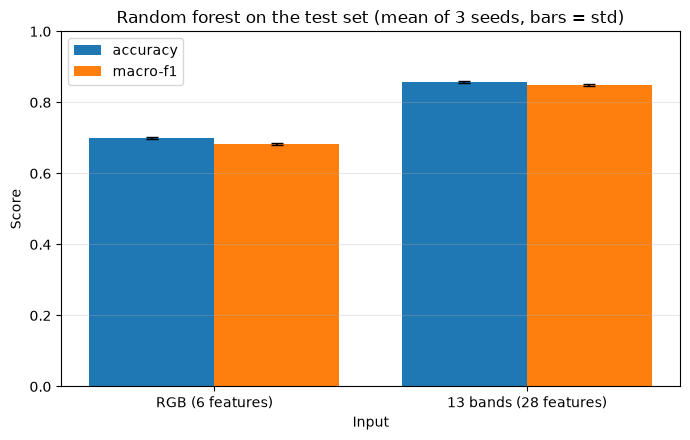


Per class test report: rgb , seed 0
                      precision    recall  f1-score   support

          AnnualCrop       0.74      0.87      0.80       429
              Forest       0.89      0.90      0.90       429
HerbaceousVegetation       0.49      0.34      0.40       428
             Highway       0.49      0.35      0.41       358
          Industrial       0.85      0.89      0.87       357
             Pasture       0.72      0.73      0.73       286
       PermanentCrop       0.47      0.51      0.49       353
         Residential       0.64      0.80      0.71       428
               River       0.65      0.62      0.63       357
             SeaLake       0.88      0.94      0.91       429

            accuracy                           0.70      3854
           macro avg       0.68      0.69      0.69      3854
        weighted avg       0.69      0.70      0.69      3854


Per class test report: 13band , seed 0
                      precision    recall  f1-score 

In [6]:
# mean and std over the 3 seeds
summary = results_df.groupby(["input","split"], sort=False)[["accuracy", "macro_f1"]].agg(["mean","std"])
summary = summary.round(4)
display(summary)

test_rows = results_df[results_df["split"]=="test"]
#print(test_rows.head())
test_scores = test_rows.groupby("input")[["accuracy","macro_f1"]].agg(["mean", "std"])

# bar plot of the test scores, error bars is the std
fig,ax = plt.subplots(figsize=(7,4.5))
x = np.arange(2)
acc_mean = test_scores.loc[["rgb", "13band"], ("accuracy","mean")]
acc_std = test_scores.loc[["rgb","13band"], ("accuracy", "std")]
f1_mean = test_scores.loc[["rgb", "13band"],("macro_f1", "mean")]
f1_std =test_scores.loc[["rgb","13band"], ("macro_f1","std")]
ax.bar(x-0.2, acc_mean, width = 0.4, yerr=acc_std,capsize=4, label="accuracy")
ax.bar(x + 0.2,f1_mean, width=0.4, yerr = f1_std, capsize=4, label="macro-f1")
ax.set_xticks(x, ["RGB (6 features)", "13 bands (28 features)"])
ax.set(title="Random forest on the test set (mean of 3 seeds, bars = std)", xlabel="Input",ylabel="Score",ylim=(0,1))
ax.legend()
ax.grid(axis="y" , alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir/ "rf_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


# same per class report as for the cnn
pred_rgb = pd.read_csv(predictions_dir / "rf_rgb_seed0.csv")
print("\nPer class test report: rgb , seed 0")
print(classification_report(pred_rgb["y_true"],pred_rgb["y_pred"], labels = label_ids,
    target_names=list(CLASS_NAMES), zero_division=0))

pred_ms = pd.read_csv(predictions_dir/"rf_13band_seed0.csv")
print("\nPer class test report: 13band , seed 0")
print(classification_report(pred_ms["y_true"], pred_ms["y_pred"],labels=label_ids,
      target_names=list(CLASS_NAMES),zero_division=0))

**Claim.** With the same model and the same patches, the 13 bands raise the random forest's test accuracy from 69.9% to 85.7% and its macro-F1 from 0.682 to 0.850, and this gain is far larger than the variation between seeds.

**Reasons.** The extra bands describe how each surface reflects red-edge, near-infrared and short-wave infrared light, which the RGB features cannot see. Everything else is the same: the split, the clipping limits, the type of model and the tuning procedure.

**Evidence.** Test accuracy 0.699 (RGB) against 0.857 (13 bands), macro-F1 0.682 against 0.850, each the mean of three seeds with a standard deviation of at most 0.003. In the per-class reports (seed 0), all four agricultural classes improve: HerbaceousVegetation from an F1 of 0.40 to 0.74, PermanentCrop from 0.49 to 0.70, AnnualCrop from 0.80 to 0.89 and Pasture from 0.73 to 0.86. River (0.63 to 0.92) and Highway (0.41 to 0.67) also gain strongly.

**Warrant.** The test patches were never used for training or tuning, so they behave like new parcels (lecture_2_introduction_to_ML.pdf, slide 24). A difference of 16 points between inputs, against a seed spread of 0.3 points, cannot come from the random draws of the forest. Because the four agricultural classes are those an insurer checks, this answers SQ1 for the baseline: the 13-band advantage holds for the random forest.

**Counterargument 1: overfitting.** The 13-band forest scores 100% on its training patches and 89% on validation, and the RGB forest 95% against 76%. Both memorise their training data (lecture_2_introduction_to_ML.pdf, slide 20). We accept this as normal for a random forest whose trees are grown until their leaves are almost pure (`max_depth=None`), which validation preferred over shallower trees (section 3). What matters for the comparison is the validation and test score, and there the 13-band forest is clearly better.

**Counterargument 2: validation is higher than test.** Validation is 6.4 points above test for RGB and 3.2 points for 13 bands. Tuning on validation explains at most the 0.7 points that tuning added. The rest comes from the spatial split: validation and test are different regions of Europe, and notebook 01 showed that some classes are concentrated in certain regions (section 7). We therefore report test scores and use the validation scores only to choose settings. That the drop is smaller for 13 bands is consistent with the extra bands transferring better between regions, but with one validation and one test set we cannot prove it.

**Counterargument 3: 100 trees may be too few.** An earlier run of this notebook with 200 trees gave a test accuracy of 0.700 (RGB) and 0.863 (13 bands), within 0.6 points of the results with 100 trees, and the seed spread is at most 0.3 points here. More trees would therefore not change the comparison.

## 6. Which features does the 13-band forest use?

A random forest records how much each feature reduced the impurity of its splits, summed over all trees (external: scikit-learn documentation, `feature_importances_`, "the impurity-based feature importances"). We average this over the three seeds. It shows which bands the advantage of the 13-band input comes from. It measures how much the forest *used* a feature, not whether the feature is necessary: when two bands carry similar information, the importance can be shared between them.

,mean,std
std_B02,0.0864,0.0007
ndvi_std,0.0642,0.0032
mean_B11,0.0522,0.0094
mean_B8A,0.0508,0.0034
mean_B12,0.0447,0.0020
mean_B09,0.0440,0.0046
std_B03,0.0438,0.0007
std_B01,0.0422,0.0055
std_B04,0.0422,0.0091
mean_B08,0.0405,0.0042


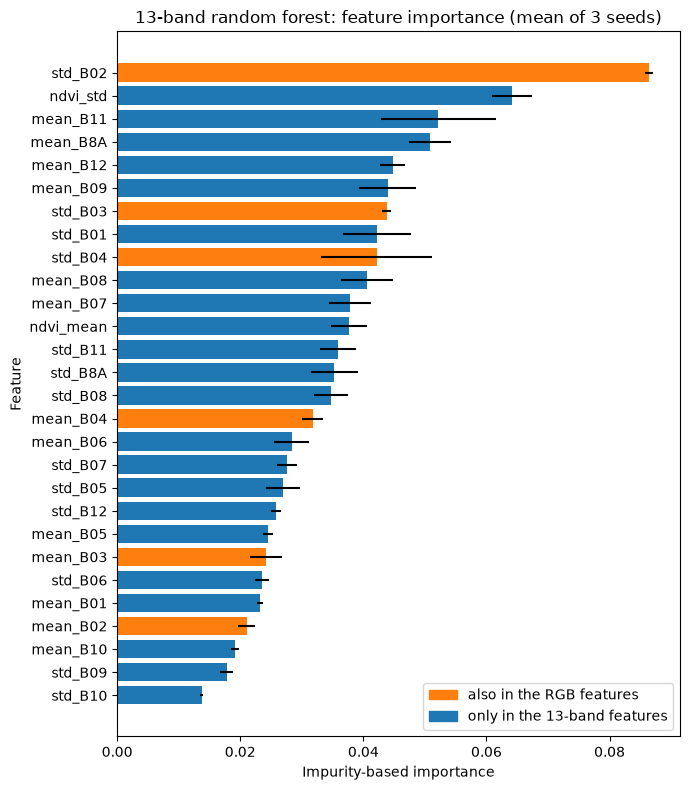

In [7]:
# feature importance for the 3 13band models
importance = {}
for seed in SEEDS:
    importance[seed] = models[("13band",seed)].feature_importances_
importance = pd.DataFrame(importance, index = MS_FEATURES)

# mean and std over the seeds, std has to be calculated before adding mean
mean_imp = importance.mean(axis=1)
std_imp = importance.std(axis = 1)
importance["mean"] = mean_imp
importance["std"]=std_imp
importance = importance.sort_values("mean")
#print(importance.head())
display(importance[["mean","std"]].sort_values("mean", ascending=False).head(10).round(4))

# orange if the feature is also in rgb, blue if its only in the 13 bands
colours = []
for name in importance.index :
    if name in RGB_FEATURES:
        colours.append("tab:orange")
    else :
        colours.append( "tab:blue")

fig, ax = plt.subplots(figsize=(7,8))
ax.barh(importance.index,importance["mean"], xerr=importance["std"], color = colours)
ax.set(title="13-band random forest: feature importance (mean of 3 seeds)",
    xlabel="Impurity-based importance",ylabel="Feature")
orange_patch = plt.Rectangle((0,0), 1, 1, color="tab:orange")
blue_patch = plt.Rectangle((0, 0),1,1, color="tab:blue")
ax.legend(handles=[orange_patch, blue_patch], labels=["also in the RGB features","only in the 13-band features"],
    loc="lower right")
plt.tight_layout()
plt.savefig(figures_dir/"rf_feature_importance_13band.png", dpi=150 , bbox_inches="tight")
plt.show()

**Claim.** The 13-band forest relies mostly on information that RGB does not have, above all the near-infrared, short-wave infrared and NDVI features. This is the source of the 13-band advantage.

**Reasons.** The bands that notebook 01 found to separate the agricultural classes are the bands the forest uses most.

**Evidence.** The 22 features that exist only in the 13-band input carry 75% of the total importance, and the 6 RGB features 25%. Among the top five, four are 13-band only: the spread of NDVI (0.064), the mean of B11 in the short-wave infrared (0.052), the mean of B8A in the near-infrared (0.051) and the mean of B12 in the short-wave infrared (0.045). The two NDVI features together carry 10%. Notebook 01 (section 6) showed that AnnualCrop, PermanentCrop, HerbaceousVegetation and Pasture overlap in B02 to B04 and spread apart from B06 to B8A and in B12.

**Warrant.** A tree can only separate two classes on a feature where their values differ, so the features it picks most are those where the classes differ most. The match between notebook 01's spectra and the importances shows that the gain comes from spectral information and not from the larger number of features alone.

**Counterargument.** Impurity-based importance shows how much the forest used a feature, not whether it needs it. Correlated bands share importance, and the single most important feature, the spread of B02 (0.086), is an RGB feature. We accept that the ranking of individual features is uncertain. The overall split of 75% against 25% is stable over the three seeds: the standard deviations of the top ten features are below 0.01.

## Summary

- The random forest uses the mean and standard deviation of each band, plus NDVI for 13 bands, with 100 trees.
- Settings were tuned on validation only, separately for each input. Only trees of depth 10 were clearly worse, and tuning changed validation macro-F1 by at most 0.7 points.
- Test results (mean of 3 seeds): RGB accuracy 0.699 and macro-F1 0.682; 13 bands accuracy 0.857 and macro-F1 0.850. The seed spread is at most 0.003.
- All four agricultural classes improve with 13 bands, HerbaceousVegetation most (F1 0.40 to 0.74). PermanentCrop remains the weakest agricultural class (0.70).
- 75% of the 13-band forest's feature importance lies in bands RGB does not have, which matches the class spectra of notebook 01.
- Both forests overfit their training data, and validation scores are higher than test scores because validation and test are different regions. All comparisons therefore use the test set.
- These predictions are the baseline that the CNN (notebook 04) and the ResNet (notebook 05) are compared with in notebook 06.

## References

Course: AI, Machine Learning & Analytics, IE University, fall 2026 (Prof. P. Delgado-Santos). Course files are cited by file name with the slide, page or section used.

**Course material**

- `lecture_2_introduction_to_ML.pdf`, lecture slides. Used: slides 16, 20, 24, 28, 30, 46 and 49.
- `ImageClassificationML.pdf`, course notebook. Used: pages 5 and 11.

**External sources**

- Helber, P., Bischke, B., Dengel, A. & Borth, D. (2019). EuroSAT: A novel dataset and deep learning benchmark for land use and land cover classification. *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing*, 12(7), 2217–2226. https://doi.org/10.1109/JSTARS.2019.2918242. Used for: the dataset.
- scikit-learn developers. `RandomForestClassifier` (including `feature_importances_`). scikit-learn documentation. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html. Used for: random forest and feature importances.
- scikit-learn developers. Glossary, `random_state`. scikit-learn documentation. https://scikit-learn.org/stable/glossary.html#term-random_state. Used for: seeds.